# FGM Prevalence, Exploratory Data Analysis

Prepares the two FGM prevalence outcomes (self-reported, women 15-49; and
daughter-reported, girls 0-14) for `FGM_Prevalence_Incidence.ipynb`, following
UNFPA Method 2's data-preparation discipline (random forest importance + VIF
pruning, re-run fresh for this outcome, per `SAE_Social Norms/00_Methodology/
01_SAE_Approach_for_FGM.md`).

This is a genuinely separate outcome from `FGM_Risk_Incidence.ipynb`: prevalence
here is the simple cumulative "ever cut" proportion (matching SDG indicator
5.3.2's own definition), not the discrete-time hazard framing risk incidence
uses. It reuses this project's own proven data-harmonization approach (region
standardization, ethnicity grouping, case-insensitive shapefile matching) rather
than the older, untested crosswalk approach in a prior reference implementation
-- this project's own approach has already been directly verified working
across several notebooks this session.

## 0. Configuration

In [1]:
country_name <- "Kenya"
country_iso3 <- "KEN"
survey_year  <- 2022

raw_year_dir       <- file.path("..", "02_Data", "raw", as.character(survey_year))
proc_data_dir      <- file.path("..", "02_Data", "processed", country_iso3)
prevalence_dir     <- file.path(proc_data_dir, "prevalence")
output_dir         <- file.path("..", "03_Outputs", country_iso3, "FGM_Prevalence")
dir.create(prevalence_dir, recursive = TRUE, showWarnings = FALSE)
dir.create(output_dir, recursive = TRUE, showWarnings = FALSE)

ir_path <- file.path(raw_year_dir, "Survey", "KEIR8CDT", "KEIR8CFL.DTA")
ge_path <- file.path(raw_year_dir, "Survey", "boundaries", "Kenya Boundaries", "shps", "sdr_subnational_boundaries.shp")

max_daughter_age <- 14   # matches SDG 5.3.2 / published FGM SAE literature convention
ethnicity_top_n   <- 8

cat("Configured for:", country_name, paste0("(", country_iso3, ")"), "\n")

Configured for: Kenya (KEN) 


## 1. Setup and packages

In [2]:
suppressMessages({
  library(tidyverse)
  library(haven)
  library(sf)
  library(randomForest)
  library(car)
})
options(repr.matrix.max.cols = Inf)
set.seed(20260101)

## 2. Load the raw individual recode and admin-1 geography

Reuses this project's own proven `standardize_region()` approach (uppercase,
alphanumeric-only) rather than the old reference notebook's name-normalization
crosswalk -- this project's version has already been directly verified to give
a clean 47/47 match against the Kenya boundary file's `DHSREGEN` field in
`FGM_Risk_Incidence.ipynb`.

In [3]:
standardize_region <- function(x) {
  x |> as.character() |> toupper() |> str_replace_all("[^A-Z ]", " ") |> str_squish()
}

ir_raw <- haven::read_dta(ir_path)
cat("Individual recode:", nrow(ir_raw), "rows,", ncol(ir_raw), "columns\n")

# The supplied Kenya spatial file contains admin-1 polygons, not
# displaced DHS cluster points. Use its verified region-code/name lookup;
# retain the original lat/lon fields as explicit NA values so downstream
# prevalence preparation keeps the same schema without inventing locations.
ge <- sf::st_read(ge_path, quiet = TRUE) |>
  sf::st_drop_geometry() |>
  dplyr::transmute(
    region_code = as.numeric(REGCODE),
    region = standardize_region(DHSREGEN),
    lat = NA_real_, lon = NA_real_,
    missing_gps = TRUE
  )
cat("Admin-1 geography lookup:", nrow(ge), "regions; cluster GPS is not supplied\n")

Individual recode: 32156 rows, 5925 columns


Admin-1 geography lookup: 47 regions; cluster GPS is not supplied


## 3. Build the self-reported (women 15-49) prevalence outcome and candidate predictors

In [4]:
# women <- ir_raw |>
#   dplyr::transmute(
#     resp_id = paste(survey_year, v001, v002, v003, sep = "-"),
#     cluster = v001,
#     weight  = v005 / 1e6,
#     psu     = v021,
#     strata  = as.numeric(v022),
#     region  = standardize_region(as_factor(sstate1)),
#     urban_rural = as_factor(v025) |> as.character(),
#     age     = as.numeric(v012),
#     education = if ("v106" %in% names(ir_raw)) as_factor(v106) |> as.character() else NA_character_,
#     religion  = if ("v130" %in% names(ir_raw)) as_factor(v130) |> as.character() else NA_character_,
#     wealth    = if ("v190" %in% names(ir_raw)) as_factor(v190) |> as.character() else NA_character_,
#     ethnicity_raw = if ("v131" %in% names(ir_raw)) as_factor(v131) |> as.character() else NA_character_,
#     fgm_heard = as_factor(g100) |> as.character(),
#     fgm_self  = dplyr::case_when(
#       as_factor(g102) == "yes" ~ 1L,
#       as_factor(g102) == "no"  ~ 0L,
#       TRUE ~ NA_integer_
#     )
#   ) |>
#   dplyr::left_join(ge, by = "cluster")

# cat("Women 15-49 with a valid self-report:", sum(!is.na(women$fgm_self)), "of", nrow(women), "\n")
# cat("Self-reported prevalence:", round(mean(women$fgm_self, na.rm = TRUE) * 100, 2), "percent\n\n")

# cat("Ethnicity categories before grouping:", dplyr::n_distinct(women$ethnicity_raw), "\n")
# ethnicity_groups <- women |> dplyr::filter(!is.na(ethnicity_raw)) |>
#   dplyr::count(ethnicity_raw, sort = TRUE) |> dplyr::slice_head(n = ethnicity_top_n) |> dplyr::pull(ethnicity_raw)
# women <- women |> dplyr::mutate(
#   ethnicity = dplyr::if_else(ethnicity_raw %in% ethnicity_groups, ethnicity_raw, "other")
# )

# IRdisplay::display(as.data.frame(head(women, 5)))

In [5]:
women <- ir_raw |>
  dplyr::transmute(
    resp_id = paste(survey_year, v001, v002, v003, sep = "-"),
    cluster = v001,
    region_code = as.numeric(v024),
    weight  = v005 / 1e6,
    psu     = v021,
    strata  = as.numeric(v022),
    urban_rural = as_factor(v025) |> as.character(),
    age     = as.numeric(v012),
    birth_year = as.numeric(v010),
    education = if ("v106" %in% names(ir_raw)) as_factor(v106) |> as.character() else NA_character_,
    religion  = if ("v130" %in% names(ir_raw)) as_factor(v130) |> as.character() else NA_character_,
    wealth    = if ("v190" %in% names(ir_raw)) as_factor(v190) |> as.character() else NA_character_,
    ethnicity_raw = if ("v131" %in% names(ir_raw)) as_factor(v131) |> as.character() else NA_character_,
    fgm_heard = as_factor(g100) |> as.character(),
    # FIX: women who said "no" to both g100 (ever heard of FGM) and g101 (the
    # follow-up probe) were skipped past g102 (personal FGM status) entirely --
    # DHS treats them as not circumcised, not as missing. The old code only
    # kept the ~23,474 women who were actually asked g102, silently dropping
    # the other 15,576 (mostly low-awareness, low-prevalence) women from the
    # denominator, which inflated the reported rate from ~14% to ~24%.
    fgm_self = dplyr::case_when(
      as_factor(g102) == "yes" ~ 1L,
      as_factor(g102) == "no"  ~ 0L,
      as_factor(g100) == "no" & as_factor(g101) == "no" ~ 0L,
      TRUE ~ NA_integer_
    )
  ) |>
  dplyr::left_join(ge, by = "region_code")

cat("Women 15-49 with a valid self-report:", sum(!is.na(women$fgm_self)), "of", nrow(women), "\n")
cat("Self-reported prevalence:", round(mean(women$fgm_self, na.rm = TRUE) * 100, 2), "percent\n\n")

cat("Ethnicity categories before grouping:", dplyr::n_distinct(women$ethnicity_raw), "\n")
ethnicity_groups <- women |> dplyr::filter(!is.na(ethnicity_raw)) |>
  dplyr::count(ethnicity_raw, sort = TRUE) |> dplyr::slice_head(n = ethnicity_top_n) |> dplyr::pull(ethnicity_raw)
women <- women |> dplyr::mutate(
  ethnicity = dplyr::if_else(ethnicity_raw %in% ethnicity_groups, ethnicity_raw, "other")
)

IRdisplay::display(as.data.frame(head(women, 5)))


Women 15-49 with a valid self-report: 16902 of 32156 


Self-reported prevalence: 23.88 percent



Ethnicity categories before grouping: 13 


resp_id,cluster,region_code,weight,psu,strata,urban_rural,age,birth_year,education,religion,wealth,ethnicity_raw,fgm_heard,fgm_self,region,lat,lon,missing_gps,ethnicity
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<dbl>,<dbl>,<lgl>,<chr>
2022-1-4-2,1,1,1.296049,1,1,urban,34,1987,no education,islam,richer,somali,yes,1,MOMBASA,NA,NA,TRUE,somali
2022-1-7-2,1,1,1.296049,1,1,urban,38,1983,secondary,catholic,richest,kamba,NA,NA,MOMBASA,NA,NA,TRUE,kamba
2022-1-10-1,1,1,1.296049,1,1,urban,33,1989,primary,catholic,richest,kikuyu,yes,0,MOMBASA,NA,NA,TRUE,kikuyu
2022-1-13-2,1,1,1.296049,1,1,urban,39,1982,secondary,catholic,richest,kamba,yes,0,MOMBASA,NA,NA,TRUE,kamba
2022-1-20-2,1,1,1.296049,1,1,urban,30,1992,primary,other,richer,mijikenda/swahili,yes,0,MOMBASA,NA,NA,TRUE,other


## 4. Build the daughter-reported (girls 0-14) prevalence outcome

Same roster-reshaping approach already verified in `00_EDA_DHS_Country_Year.ipynb`
(`gidx`/`g121`/`g122` linked to `bidx`/`b8`), restricted here to daughters aged
0-14 specifically, matching SDG 5.3.2's own age convention and the published
Senegal/Kenya FGM small-area mapping papers this pipeline follows.

In [6]:
# gidx_cols <- names(ir_raw)[str_detect(names(ir_raw), "^gidx_[0-9]{2}$")]

# daughter_roster <- ir_raw |>
#   dplyr::mutate(resp_id = paste(survey_year, v001, v002, v003, sep = "-"),
#                 dplyr::across(dplyr::matches("^g121_[0-9]{2}$"), ~ as_factor(.) |> as.character())) |>
#   dplyr::select(resp_id, dplyr::matches("^gidx_[0-9]{2}$"), dplyr::matches("^g121_[0-9]{2}$")) |>
#   tidyr::pivot_longer(-resp_id, names_to = c(".value", "slot"), names_pattern = "^(gidx|g121)_([0-9]{2})$") |>
#   dplyr::filter(!is.na(gidx)) |>
#   dplyr::transmute(resp_id, birth_order = as.integer(gidx),
#                     fgm_daughter = dplyr::case_when(g121 == "yes" ~ 1L, g121 == "no" ~ 0L, TRUE ~ NA_integer_))

# daughter_ages <- ir_raw |>
#   dplyr::mutate(resp_id = paste(survey_year, v001, v002, v003, sep = "-")) |>
#   dplyr::select(resp_id, dplyr::matches("^bidx_[0-9]{2}$"), dplyr::matches("^b8_[0-9]{2}$")) |>
#   tidyr::pivot_longer(-resp_id, names_to = c(".value", "slot"), names_pattern = "^(bidx|b8)_([0-9]{2})$") |>
#   dplyr::filter(!is.na(bidx)) |>
#   dplyr::transmute(resp_id, birth_order = as.integer(bidx), daughter_age = as.numeric(b8))

# daughters <- daughter_roster |>
#   dplyr::inner_join(daughter_ages, by = c("resp_id", "birth_order")) |>
#   dplyr::filter(!is.na(fgm_daughter), !is.na(daughter_age), daughter_age <= max_daughter_age) |>
#   dplyr::left_join(
#     women |> dplyr::select(resp_id, cluster, weight, psu, strata, region, urban_rural,
#                             education, religion, wealth, ethnicity, lat, lon, missing_gps),
#     by = "resp_id"
#   ) |>
#   dplyr::mutate(age = daughter_age)

# cat("Daughters 0-14 with a valid report:", sum(!is.na(daughters$fgm_daughter)), "\n")
# cat("Daughter-reported prevalence:", round(mean(daughters$fgm_daughter, na.rm = TRUE) * 100, 2), "percent\n\n")
# IRdisplay::display(as.data.frame(head(daughters, 5)))

In [7]:
gidx_cols <- names(ir_raw)[str_detect(names(ir_raw), "^gidx_[0-9]{2}$")]

daughter_roster <- ir_raw |>
  dplyr::mutate(resp_id = paste(survey_year, v001, v002, v003, sep = "-"),
                dplyr::across(dplyr::matches("^g121_[0-9]{2}$"), ~ as_factor(.) |> as.character())) |>
  dplyr::select(resp_id, dplyr::matches("^gidx_[0-9]{2}$"), dplyr::matches("^g121_[0-9]{2}$")) |>
  tidyr::pivot_longer(-resp_id, names_to = c(".value", "slot"), names_pattern = "^(gidx|g121)_([0-9]{2})$") |>
  dplyr::filter(!is.na(gidx)) |>
  dplyr::transmute(resp_id, birth_order = as.integer(gidx),
                    fgm_daughter_reported = dplyr::case_when(g121 == "yes" ~ 1L, g121 == "no" ~ 0L, TRUE ~ NA_integer_))

# Full birth-history list of living daughters 0-14, independent of the gidx
# roster -- needed because mothers who were skipped past the FGM module never
# get a gidx entry for their daughters at all, not even a missing one.
daughter_birth_history <- ir_raw |>
  dplyr::mutate(resp_id = paste(survey_year, v001, v002, v003, sep = "-"),
                fgm_heard_no = as_factor(g100) == "no",
                fgm_probe_no = as_factor(g101) == "no") |>
  dplyr::select(resp_id, fgm_heard_no, fgm_probe_no,
                dplyr::matches("^bidx_[0-9]{2}$"), dplyr::matches("^b2_[0-9]{2}$"),
                dplyr::matches("^b4_[0-9]{2}$"), dplyr::matches("^b5_[0-9]{2}$"),
                dplyr::matches("^b8_[0-9]{2}$")) |>
  dplyr::mutate(dplyr::across(dplyr::matches("^b4_[0-9]{2}$"), ~ as_factor(.) |> as.character()),
                dplyr::across(dplyr::matches("^b5_[0-9]{2}$"), ~ as_factor(.) |> as.character())) |>
  tidyr::pivot_longer(dplyr::matches("^(bidx|b2|b4|b5|b8)_[0-9]{2}$"),
                        names_to = c(".value", "slot"), names_pattern = "^(bidx|b2|b4|b5|b8)_([0-9]{2})$") |>
  dplyr::filter(!is.na(bidx), b4 == "female", b5 == "yes") |>
  dplyr::transmute(resp_id, birth_order = as.integer(bidx),
                    daughter_age = as.numeric(b8), birth_year = as.numeric(b2),
                    fgm_heard_no, fgm_probe_no) |>
  dplyr::filter(!is.na(daughter_age), daughter_age <= max_daughter_age)

daughters_reported <- daughter_birth_history |>
  dplyr::inner_join(daughter_roster, by = c("resp_id", "birth_order")) |>
  dplyr::filter(!is.na(fgm_daughter_reported)) |>
  dplyr::transmute(resp_id, birth_order, daughter_age, birth_year, fgm_daughter = fgm_daughter_reported)

# DHS convention: mothers who never heard of FGM at all (g100 == "no" AND
# g101 == "no") skip the entire daughter module -- their daughters are
# assumed not circumcised, same skip-pattern logic as the fix above.
daughters_imputed <- daughter_birth_history |>
  dplyr::filter(fgm_heard_no, fgm_probe_no) |>
  dplyr::anti_join(daughters_reported, by = c("resp_id", "birth_order")) |>
  dplyr::transmute(resp_id, birth_order, daughter_age, birth_year, fgm_daughter = 0L)

daughters <- dplyr::bind_rows(daughters_reported, daughters_imputed) |>
  dplyr::left_join(
    women |> dplyr::select(resp_id, cluster, weight, psu, strata, region, urban_rural,
                            education, religion, wealth, ethnicity, lat, lon, missing_gps),
    by = "resp_id"
  ) |>
  dplyr::mutate(age = daughter_age)

cat("Daughters 0-14, reported directly:", nrow(daughters_reported), "\n")
cat("Daughters 0-14, imputed as not-circumcised (mother never heard of FGM):", nrow(daughters_imputed), "\n")
cat("Daughters 0-14 total:", nrow(daughters), "\n")
cat("Daughter-reported prevalence:", round(mean(daughters$fgm_daughter, na.rm = TRUE) * 100, 2), "percent\n\n")
IRdisplay::display(as.data.frame(head(daughters, 5)))


Daughters 0-14, reported directly: 13091 


Daughters 0-14, imputed as not-circumcised (mother never heard of FGM): 434 


Daughters 0-14 total: 13525 


Daughter-reported prevalence: 5.09 percent



resp_id,birth_order,daughter_age,birth_year,fgm_daughter,cluster,weight,psu,strata,region,urban_rural,education,religion,wealth,ethnicity,lat,lon,missing_gps,age
<chr>,<int>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<lgl>,<dbl>
2022-1-4-2,3,11,2010,0,1,1.296049,1,1,MOMBASA,urban,no education,islam,richer,somali,NA,NA,TRUE,11
2022-1-13-2,1,3,2019,0,1,1.296049,1,1,MOMBASA,urban,secondary,catholic,richest,kamba,NA,NA,TRUE,3
2022-1-13-2,2,5,2016,0,1,1.296049,1,1,MOMBASA,urban,secondary,catholic,richest,kamba,NA,NA,TRUE,5
2022-1-20-2,1,5,2016,0,1,1.296049,1,1,MOMBASA,urban,primary,other,richer,other,NA,NA,TRUE,5
2022-1-26-2,2,6,2015,0,1,1.296049,1,1,MOMBASA,urban,secondary,evangelical churches,richer,kamba,NA,NA,TRUE,6


## 5. Feature importance -- random forest (self-reported outcome)

In [8]:
candidate_predictors <- c("age", "education", "religion", "ethnicity", "wealth", "urban_rural", "region")

missingness <- women |> dplyr::select(dplyr::all_of(candidate_predictors)) |>
  dplyr::summarise(dplyr::across(dplyr::everything(), ~ mean(is.na(.)))) |>
  tidyr::pivot_longer(dplyr::everything(), names_to = "variable", values_to = "pct_missing")
cat("=== Missingness by candidate predictor ===\n")
print(missingness)

keep_predictors <- missingness |> dplyr::filter(pct_missing < 0.30) |> dplyr::pull(variable)
cat("\nRetained after the 30% missingness screen:", paste(keep_predictors, collapse = ", "), "\n\n")

rf_data <- women |>
  dplyr::filter(!is.na(fgm_self)) |>
  dplyr::select(fgm_self, dplyr::all_of(keep_predictors)) |>
  tidyr::drop_na() |>
  dplyr::mutate(
    fgm_self = factor(fgm_self),
    dplyr::across(dplyr::where(is.character), as.factor)
  )
cat("N rows for importance screen:", nrow(rf_data), "\n")

rf_model <- randomForest::randomForest(fgm_self ~ ., data = rf_data, ntree = 500, importance = TRUE)
rf_importance <- randomForest::importance(rf_model)
rf_importance_ranked <- rf_importance[order(-rf_importance[, "MeanDecreaseGini"]), ]

cat("\n=== Variable importance, ranked ===\n")
print(rf_importance_ranked)

readr::write_csv(tibble::as_tibble(rf_importance_ranked, rownames = "variable"),
                  file.path(output_dir, paste0(country_iso3, "_prevalence_feature_importance.csv")))

=== Missingness by candidate predictor ===


# A tibble: 7 × 2
  variable    pct_missing
  <chr>             <dbl>
1 age                   0
2 education             0
3 religion              0
4 ethnicity             0
5 wealth                0
6 urban_rural           0
7 region                0



Retained after the 30% missingness screen: age, education, religion, ethnicity, wealth, urban_rural, region 



N rows for importance screen: 16902 



=== Variable importance, ranked ===


                   0        1 MeanDecreaseAccuracy MeanDecreaseGini
region      82.05220 51.60154            140.83429       2153.86137
ethnicity   66.87047 57.13072             78.78747       1171.01892
religion    22.93930 35.09986             37.75302        549.67636
age         35.37946 82.11699             74.35249        512.61018
education   27.48926 54.18234             46.52607        397.48372
wealth      23.44945 33.27496             34.82779        270.54285
urban_rural 19.00753 25.89813             32.99345         67.05558


=== Missingness among candidate predictors ===


# A tibble: 7 × 3
  variable    proportion_missing percent_missing
  <chr>                    <dbl>           <dbl>
1 age                          0               0
2 education                    0               0
3 religion                     0               0
4 ethnicity                    0               0
5 wealth                       0               0
6 urban_rural                  0               0
7 region                       0               0



Predictors retained after the 30% missingness screen:
 age, education, religion, ethnicity, wealth, urban_rural, region 



Rows available before pairwise missing-value handling: 16902 



=== Mixed-variable association matrix ===


            fgm_self   age education religion ethnicity wealth urban_rural
fgm_self       1.000 0.104     0.436    0.459     0.640  0.312       0.082
age            0.104 1.000     0.280    0.064     0.103  0.035       0.025
education      0.436 0.280     1.000    0.275     0.325  0.356       0.258
religion       0.459 0.064     0.275    1.000     0.301  0.133       0.122
ethnicity      0.640 0.103     0.325    0.301     1.000  0.208       0.175
wealth         0.312 0.035     0.356    0.133     0.208  1.000       0.651
urban_rural    0.082 0.025     0.258    0.122     0.175  0.651       1.000
region         0.698 0.119     0.374    0.331     0.786  0.299       0.376
            region
fgm_self     0.698
age          0.119
education    0.374
religion     0.331
ethnicity    0.786
wealth       0.299
urban_rural  0.376
region       1.000



=== Predictor association with FGM status ===


# A tibble: 7 × 2
  predictor association_with_fgm
  <chr>                    <dbl>
1 State                   0.698 
2 Ethnicity               0.640 
3 Religion                0.459 
4 Education               0.436 
5 Wealth                  0.312 
6 Age                     0.104 
7 Residence               0.0816


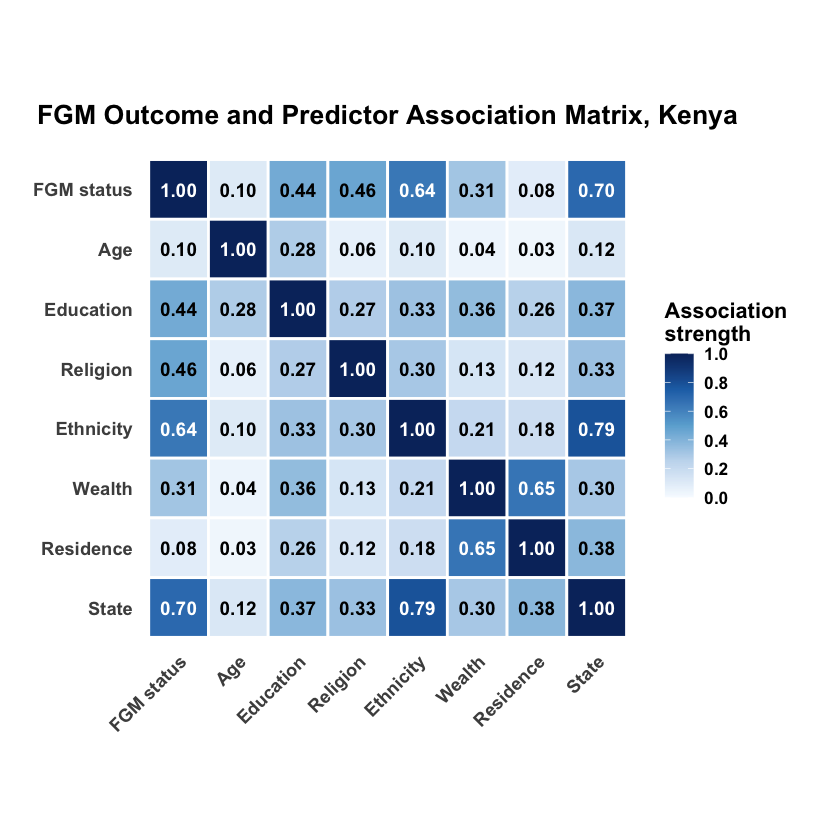

In [9]:
# ================================================================
# 5. Mixed-variable association matrix
# ================================================================
#
# Numeric versus numeric:
#   Absolute Spearman correlation
#
# Categorical versus categorical:
#   Bias-corrected Cramer's V
#
# Numeric versus categorical:
#   Correlation ratio (eta)
#
# Values range from 0 to 1:
#   0 = no association
#   1 = strongest association
# ================================================================

candidate_predictors <- c(
  "age",
  "education",
  "religion",
  "ethnicity",
  "wealth",
  "urban_rural",
  "region"
)

# ------------------------------------------------
# 5.1 Examine predictor missingness
# ------------------------------------------------

missingness <- women |>
  dplyr::select(
    dplyr::all_of(candidate_predictors)
  ) |>
  dplyr::summarise(
    dplyr::across(
      dplyr::everything(),
      ~ mean(is.na(.))
    )
  ) |>
  tidyr::pivot_longer(
    cols = dplyr::everything(),
    names_to = "variable",
    values_to = "proportion_missing"
  ) |>
  dplyr::mutate(
    percent_missing = 100 * proportion_missing
  )

cat("=== Missingness among candidate predictors ===\n")
print(missingness)

# Retain predictors with less than 30% missingness
keep_predictors <- missingness |>
  dplyr::filter(proportion_missing < 0.30) |>
  dplyr::pull(variable)

cat(
  "\nPredictors retained after the 30% missingness screen:\n",
  paste(keep_predictors, collapse = ", "),
  "\n"
)

# ------------------------------------------------
# 5.2 Prepare the association data
# ------------------------------------------------

association_data <- women |>
  dplyr::filter(!is.na(fgm_self)) |>
  dplyr::select(
    fgm_self,
    dplyr::all_of(keep_predictors)
  ) |>
  dplyr::mutate(
    fgm_self = factor(
      fgm_self,
      levels = c(0, 1),
      labels = c("Not cut", "Cut")
    ),
    dplyr::across(
      dplyr::where(haven::is.labelled),
      ~ factor(haven::as_factor(.))
    ),
    dplyr::across(
      dplyr::where(is.character),
      as.factor
    )
  )

cat(
  "\nRows available before pairwise missing-value handling:",
  nrow(association_data),
  "\n"
)

# ------------------------------------------------
# 5.3 Bias-corrected Cramer's V
# ------------------------------------------------

cramers_v_corrected <- function(x, y) {

  valid <- stats::complete.cases(x, y)

  x <- droplevels(as.factor(x[valid]))
  y <- droplevels(as.factor(y[valid]))

  if (
    length(x) == 0 ||
    nlevels(x) < 2 ||
    nlevels(y) < 2
  ) {
    return(NA_real_)
  }

  contingency_table <- table(x, y)

  if (
    nrow(contingency_table) < 2 ||
    ncol(contingency_table) < 2
  ) {
    return(NA_real_)
  }

  chi_result <- suppressWarnings(
    stats::chisq.test(
      contingency_table,
      correct = FALSE
    )
  )

  chi_squared <- as.numeric(
    chi_result$statistic
  )

  sample_size <- sum(contingency_table)
  number_rows <- nrow(contingency_table)
  number_columns <- ncol(contingency_table)

  phi_squared <- chi_squared / sample_size

  phi_squared_corrected <- max(
    0,
    phi_squared -
      (
        (number_columns - 1) *
          (number_rows - 1)
      ) /
      (sample_size - 1)
  )

  rows_corrected <- number_rows -
    ((number_rows - 1)^2) /
    (sample_size - 1)

  columns_corrected <- number_columns -
    ((number_columns - 1)^2) /
    (sample_size - 1)

  denominator <- min(
    rows_corrected - 1,
    columns_corrected - 1
  )

  if (
    !is.finite(denominator) ||
    denominator <= 0
  ) {
    return(NA_real_)
  }

  sqrt(
    phi_squared_corrected /
      denominator
  )
}

# ------------------------------------------------
# 5.4 Correlation ratio
# ------------------------------------------------

correlation_ratio <- function(
  numeric_variable,
  categorical_variable
) {

  valid <- stats::complete.cases(
    numeric_variable,
    categorical_variable
  )

  numeric_variable <- as.numeric(
    numeric_variable[valid]
  )

  categorical_variable <- droplevels(
    as.factor(
      categorical_variable[valid]
    )
  )

  if (
    length(numeric_variable) == 0 ||
    length(unique(numeric_variable)) < 2 ||
    nlevels(categorical_variable) < 2
  ) {
    return(NA_real_)
  }

  overall_mean <- mean(
    numeric_variable
  )

  group_information <- split(
    numeric_variable,
    categorical_variable
  )

  between_group_variation <- sum(
    vapply(
      group_information,
      function(group_values) {

        length(group_values) *
          (
            mean(group_values) -
              overall_mean
          )^2
      },
      numeric(1)
    )
  )

  total_variation <- sum(
    (
      numeric_variable -
        overall_mean
    )^2
  )

  if (
    !is.finite(total_variation) ||
    total_variation <= 0
  ) {
    return(NA_real_)
  }

  eta_squared <- between_group_variation /
    total_variation

  sqrt(
    max(
      0,
      min(1, eta_squared)
    )
  )
}

# ------------------------------------------------
# 5.5 Select the appropriate association measure
# ------------------------------------------------

mixed_association <- function(x, y) {

  x_numeric <- is.numeric(x)
  y_numeric <- is.numeric(y)

  # Numeric versus numeric
  if (x_numeric && y_numeric) {

    valid <- stats::complete.cases(x, y)

    if (
      sum(valid) < 3 ||
      length(unique(x[valid])) < 2 ||
      length(unique(y[valid])) < 2
    ) {
      return(NA_real_)
    }

    return(
      abs(
        stats::cor(
          x[valid],
          y[valid],
          method = "spearman"
        )
      )
    )
  }

  # Categorical versus categorical
  if (!x_numeric && !y_numeric) {

    return(
      cramers_v_corrected(x, y)
    )
  }

  # Numeric versus categorical
  if (x_numeric && !y_numeric) {

    return(
      correlation_ratio(x, y)
    )
  }

  # Categorical versus numeric
  correlation_ratio(y, x)
}

# ------------------------------------------------
# 5.6 Calculate the association matrix
# ------------------------------------------------

variable_names <- names(
  association_data
)

association_matrix <- matrix(
  NA_real_,
  nrow = length(variable_names),
  ncol = length(variable_names),
  dimnames = list(
    variable_names,
    variable_names
  )
)

for (
  row_index in seq_along(variable_names)
) {

  for (
    column_index in seq_along(variable_names)
  ) {

    if (row_index == column_index) {

      association_matrix[
        row_index,
        column_index
      ] <- 1

    } else {

      association_matrix[
        row_index,
        column_index
      ] <- mixed_association(
        association_data[[row_index]],
        association_data[[column_index]]
      )
    }
  }
}

# Display the numerical matrix
cat("\n=== Mixed-variable association matrix ===\n")
print(
  round(
    association_matrix,
    digits = 3
  )
)

# ------------------------------------------------
# 5.7 Convert the matrix to plotting format
# ------------------------------------------------

display_labels <- c(
  fgm_self = "FGM status",
  age = "Age",
  education = "Education",
  religion = "Religion",
  ethnicity = "Ethnicity",
  wealth = "Wealth",
  urban_rural = "Residence",
  region = "State"
)

matrix_long <- association_matrix |>
  as.data.frame() |>
  tibble::rownames_to_column(
    "variable_y"
  ) |>
  tidyr::pivot_longer(
    cols = -variable_y,
    names_to = "variable_x",
    values_to = "association"
  ) |>
  dplyr::mutate(
    variable_x_label = dplyr::recode(
      variable_x,
      !!!display_labels
    ),
    variable_y_label = dplyr::recode(
      variable_y,
      !!!display_labels
    )
  )

ordered_labels <- unname(
  display_labels[variable_names]
)

matrix_long <- matrix_long |>
  dplyr::mutate(
    variable_x_label = factor(
      variable_x_label,
      levels = ordered_labels
    ),
    variable_y_label = factor(
      variable_y_label,
      levels = rev(ordered_labels)
    ),
    value_label = dplyr::if_else(
      is.na(association),
      "NA",
      sprintf("%.2f", association)
    )
  )

# ------------------------------------------------
# 5.8 Plot the association matrix
# ------------------------------------------------

association_matrix_plot <- ggplot2::ggplot(
  matrix_long,
  ggplot2::aes(
    x = variable_x_label,
    y = variable_y_label,
    fill = association
  )
) +
  ggplot2::geom_tile(
    color = "white",
    linewidth = 0.8
  ) +
  ggplot2::geom_text(
    ggplot2::aes(
      label = value_label,
      color = association >= 0.55
    ),
    fontface = "bold",
    size = 4
  ) +
  ggplot2::scale_fill_gradientn(
    colors = c(
      "#F7FBFF",
      "#C6DBEF",
      "#6BAED6",
      "#2171B5",
      "#08306B"
    ),
    limits = c(0, 1),
    breaks = seq(
      0,
      1,
      by = 0.2
    ),
    labels = scales::number_format(
      accuracy = 0.1
    ),
    na.value = "grey85",
    name = "Association\nstrength"
  ) +
  ggplot2::scale_color_manual(
    values = c(
      `FALSE` = "black",
      `TRUE` = "white"
    ),
    guide = "none"
  ) +
  ggplot2::coord_fixed() +
  ggplot2::labs(
    title = paste(
      "FGM Outcome and Predictor Association Matrix,",
      country_name
    ),
    x = NULL,
    y = NULL
  ) +
  ggplot2::theme_minimal(
    base_size = 13
  ) +
  ggplot2::theme(
    plot.title = ggplot2::element_text(
      face = "bold",
      size = 16,
      hjust = 0.5,
      margin = ggplot2::margin(
        b = 15
      )
    ),
    axis.text.x = ggplot2::element_text(
      face = "bold",
      angle = 45,
      hjust = 1,
      vjust = 1,
      size = 11
    ),
    axis.text.y = ggplot2::element_text(
      face = "bold",
      size = 11
    ),
    legend.title = ggplot2::element_text(
      face = "bold"
    ),
    legend.text = ggplot2::element_text(
      face = "bold"
    ),
    panel.grid = ggplot2::element_blank(),
    plot.margin = ggplot2::margin(
      20,
      25,
      20,
      20
    )
  )

print(
  association_matrix_plot
)

# ------------------------------------------------
# 5.9 Rank predictors by association with FGM
# ------------------------------------------------

outcome_association_ranking <- matrix_long |>
  dplyr::filter(
    variable_y == "fgm_self",
    variable_x != "fgm_self"
  ) |>
  dplyr::arrange(
    dplyr::desc(association)
  ) |>
  dplyr::transmute(
    predictor = as.character(
      variable_x_label
    ),
    association_with_fgm = association
  )

cat(
  "\n=== Predictor association with FGM status ===\n"
)

print(
  outcome_association_ranking
)

# ------------------------------------------------
# 5.10 Save the matrix and predictor ranking
# ------------------------------------------------

readr::write_csv(
  matrix_long |>
    dplyr::select(
      variable_y,
      variable_x,
      association
    ),
  file.path(
    output_dir,
    paste0(
      country_iso3,
      "_prevalence_association_matrix.csv"
    )
  )
)

readr::write_csv(
  outcome_association_ranking,
  file.path(
    output_dir,
    paste0(
      country_iso3,
      "_prevalence_predictor_association_ranking.csv"
    )
  )
)

ggplot2::ggsave(
  filename = file.path(
    output_dir,
    paste0(
      country_iso3,
      "_prevalence_association_matrix.png"
    )
  ),
  plot = association_matrix_plot,
  width = 10,
  height = 8,
  units = "in",
  dpi = 300,
  bg = "white"
)

## 6. Collinearity check -- VIF

In [10]:
vif_check_model <- glm(fgm_self ~ ., data = rf_data, family = binomial())
vif_table <- car::vif(vif_check_model)
vif_adjusted <- if (is.matrix(vif_table)) vif_table[, "GVIF^(1/(2*Df))"] else sqrt(vif_table)

cat("=== Collinearity (adjusted VIF, > ~2 is worth a closer look) ===\n")
print(sort(vif_adjusted, decreasing = TRUE))

vif_flagged <- names(vif_adjusted)[vif_adjusted > 2]
if (length(vif_flagged) == 0) {
  cat("\nNo predictor exceeds the adjusted-VIF concern threshold, all candidates retained.\n")
} else {
  cat("\nFlagged for possible removal (adjusted VIF > 2):", paste(vif_flagged, collapse = ", "), "\n")
}

selected_predictors <- setdiff(rownames(rf_importance_ranked), vif_flagged)
cat("\nFinal predictor list, ranked by importance:\n")
print(selected_predictors)

=== Collinearity (adjusted VIF, > ~2 is worth a closer look) ===


  ethnicity urban_rural         age      wealth   education    religion 
   1.467045    1.447614    1.248315    1.144517    1.124796    1.098771 
     region 
   1.075967 



No predictor exceeds the adjusted-VIF concern threshold, all candidates retained.



Final predictor list, ranked by importance:


[1] "region"      "ethnicity"   "religion"    "age"         "education"  
[6] "wealth"      "urban_rural"


## 7. Save the processed outputs

In [11]:
saveRDS(women, file.path(prevalence_dir, paste0(country_iso3, "_prevalence_self.rds")))
readr::write_csv(women, file.path(prevalence_dir, paste0(country_iso3, "_prevalence_self.csv")))
saveRDS(daughters, file.path(prevalence_dir, paste0(country_iso3, "_prevalence_daughter.rds")))
readr::write_csv(daughters, file.path(prevalence_dir, paste0(country_iso3, "_prevalence_daughter.csv")))
saveRDS(selected_predictors, file.path(prevalence_dir, paste0(country_iso3, "_prevalence_selected_predictors.rds")))

cat("Written to", prevalence_dir, "\n")
cat("Ready for FGM_Prevalence_Incidence.ipynb\n")

Written to ../02_Data/processed/KEN/prevalence 


Ready for FGM_Prevalence_Incidence.ipynb
